# Base Modeling

### 1. Conectar con Google Drive e importar librerías

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

In [2]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  !rm -rf vms
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  print(RUTA_DATOS)

Running local
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\notebooks\modeling\..\..\data


In [3]:
if IN_COLAB:  
  !git clone https://github.com/kamimartinez/VMS-prediction.git vms
  def change_branch(branch):
    !git -C vms checkout {branch}
  # change_branch("feat/lstm")
  sys.path.append(os.path.abspath("vms/notebooks"))

In [4]:
if IN_COLAB:
  !ls vms/notebooks

### 2. Cargar el dataset final
Se lee desde `Datos/Procesado`. Si no existe, primero hay que ejecutar `DataPreparation.ipynb` completo.

In [5]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

### 3. Parámetros

* `USAR_VACAS`: incluye `vacas_activas_dia` como covariable (recomendado: el cambio de prevalencia viene del crecimiento del hato).
* `USAR_CLASS_WEIGHT`: el `balanced` se calcula con la prevalencia de train (≈15 %), que no es la de val/test; por eso va apagado. El umbral se ajusta en validación.
* `VIDA_MEDIA_DIAS`: peso temporal exponencial (los datos recientes pesan más). `None` lo desactiva.

In [6]:
TARGET = "pct_posible_cola"
N_FOLDS = 5
CORTE_COLA = 0.5          # definición del evento: pct_posible_cola > CORTE_COLA
SEED = 42

USAR_VACAS = True
USAR_CLASS_WEIGHT = False
VIDA_MEDIA_DIAS = 180     # None para desactivar

# Normalización de datos

In [7]:
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = load_dataset()
df = df.sort_values(["ms", "bloque_tiempo"]).reset_index(drop=True)

g = df.groupby("ms")
contiguo = (df["bloque_tiempo"] - g["bloque_tiempo"].shift(1)) == pd.Timedelta("30min")

COLS_ORDENIO = [
    "total_ordenios",
    "duracion_total_min",
    "pct_ocupacion_robot",
    "hubo_ordenios",
]
cols_lag = [c for c in COLS_ORDENIO if c in df.columns]

for c in cols_lag:
    df[f"{c}_anterior"] = g[c].shift(1).where(contiguo)

df["pct_cola_anterior"] = g[TARGET].shift(1).where(contiguo)

# --- Codificación cíclica (23h está al lado de 0h; domingo al lado de lunes)
df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)
df["dia_sin"] = np.sin(2 * np.pi * df["dia_semana"] / 7)
df["dia_cos"] = np.cos(2 * np.pi * df["dia_semana"] / 7)

df["cola"] = (df[TARGET] > CORTE_COLA).astype("float32")

# Orden temporal ESTABLE: los 3 VMS comparten timestamp, el desempate por ms evita que el corte parta un bloque
df = df.sort_values(["bloque_tiempo", "ms"], kind="stable").reset_index(drop=True)

df_clean = df.drop(columns=cols_lag).dropna(subset=["pct_cola_anterior"]).copy().reset_index(drop=True)

# drop_first=True: evita colinealidad exacta con el intercepto
df_clean = pd.get_dummies(df_clean, columns=["ms", "temporada"], dtype="float32", drop_first=True)

# vacas_activas_dia se mantiene (se selecciona con USAR_VACAS más adelante)
DROP_COLUMNS = [TARGET, "bloque_tiempo", "cola", "produccion_promedio", "sin_etapa", "hora", "dia_semana"]
y_all = df_clean["cola"].values
X_full = df_clean.drop(columns=DROP_COLUMNS)
print(X_full.columns)


def construir_preprocesador(X):
    """Escala numéricas (imputa 0 + StandardScaler) y deja las dummies tal cual."""
    dummies = [c for c in X.columns if c.startswith(("ms_", "temporada_"))]
    categoricas = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    numericas = [
        c for c in X.select_dtypes(include="number").columns
        if c not in dummies and c != "cola"
    ]
    num_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
            ("scaler", StandardScaler()),
        ]
    )
    pre = ColumnTransformer(
        transformers=[
            ("num", num_pipeline, numericas),
            ("bin", "passthrough", dummies),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    pre.set_output(transform="pandas")
    return pre


preprocessor = construir_preprocesador(X_full)
# OJO: ya NO se hace fit_transform sobre todo X. El ajuste se hace solo con train en el bloque siguiente.

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']
Index(['patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado',
       'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja',
       'pct_extendida', 'hubo_lavado', 'ordenios_otros_robots',
       'min_desde_alimento', 'vacas_activas_dia', 'total_ordenios_anterior',
       'duracion_total_min_anterior', 'pct_ocupacion_robot_anterior',
       'hubo_ordenios_anterior', 'pct_cola_anterior', 'hora_sin', 'hora_cos',
       'dia_sin', 'dia_cos', 'ms_VMS 2', 'ms_VMS 3', 'temporada_otoño',
       'temporada_primave

# Separación de train y tests

In [8]:
n = len(X_full)
n_train, n_val = int(n * 0.70), int(n * 0.85)

preprocessor.fit(X_full.iloc[:n_train])                      # solo train
X_all_full = preprocessor.transform(X_full).astype("float32")
feature_names_full = list(X_all_full.columns)
X_all_full = X_all_full.values

# Selección de columnas según USAR_VACAS
sel = [i for i, c in enumerate(feature_names_full) if USAR_VACAS or c != "vacas_activas_dia"]
feature_names = [feature_names_full[i] for i in sel]
X_all = X_all_full[:, sel]

t_obj = np.arange(len(X_all))

train = t_obj < n_train
val = (t_obj >= n_train) & (t_obj < n_val)
test = t_obj >= n_val

X_train, y_train = X_all[train], y_all[train]
X_val, y_val = X_all[val], y_all[val]
X_test, y_test = X_all[test], y_all[test]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("pct cola -> train: %.3f | val: %.3f | test: %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

fechas = df_clean["bloque_tiempo"].values

splits = {"Train": train, "Val": val, "Test": test}

print("=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===")
for nombre, mascara in splits.items():
    indices_bloque = t_obj[mascara]
    fecha_inicio = np.datetime_as_string(fechas[indices_bloque[0]]).split("T")[0]
    fecha_fin = np.datetime_as_string(fechas[indices_bloque[-1]]).split("T")[0]
    print(f"{nombre:<6} | Inicio: {fecha_inicio} | Fin: {fecha_fin} | Ventanas: {len(indices_bloque)}")

X_train: (125892, 26) | X_val: (26977, 26) | X_test: (26978, 26)
pct cola -> train: 0.147 | val: 0.425 | test: 0.575
=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===
Train  | Inicio: 2022-08-01 | Fin: 2024-12-22 | Ventanas: 125892
Val    | Inicio: 2024-12-22 | Fin: 2025-06-27 | Ventanas: 26977
Test   | Inicio: 2025-06-27 | Fin: 2025-12-31 | Ventanas: 26978


# Modelo

In [9]:
if IN_COLAB:
  from modeling.model_base import BaseModel
  from modeling.lr import LogisticRegression
else:
  from model_base import BaseModel
  from lr import LogisticRegression
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from pathlib import Path

model_path = Path.cwd()
tf.keras.utils.set_random_seed(SEED)

model_base = LogisticRegression()

model = model_base.compile(input_shape=(X_train.shape[1],))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27 (108.00 B)

 Trainable params: 27 (108.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
def pesos_temporales(fechas_tr, vida_media_dias):
    """Peso exponencial: un dato con `vida_media_dias` de antigüedad pesa la mitad que el más reciente."""
    if vida_media_dias is None:
        return None
    dias = (fechas_tr.max() - fechas_tr) / np.timedelta64(1, "D")
    w = 0.5 ** (dias / vida_media_dias)
    return (w / w.mean()).astype("float32")      # media 1 para no alterar la escala de la loss


callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint(
        model_path / ".." / ".." / "models" / "logistic_regresion.keras", monitor="val_loss", save_best_only=True
    ),
]

class_weight = None
if USAR_CLASS_WEIGHT:
    cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
    class_weight = {0: cw[0], 1: cw[1]}
print("class_weight:", class_weight)

sample_weight = pesos_temporales(fechas[train], VIDA_MEDIA_DIAS)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    class_weight=class_weight,
    sample_weight=sample_weight,
    callbacks=callbacks,
    shuffle=True,
    verbose=1,
)

print("Model Finished")

class_weight: None
Epoch 1/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.7244 - auc: 0.5908 - loss: 0.6140 - precision: 0.1925 - recall: 0.2754 - val_accuracy: 0.5838 - val_auc: 0.6510 - val_loss: 0.6671 - val_precision: 0.5559 - val_recall: 0.1071
Epoch 2/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8456 - auc: 0.7532 - loss: 0.4924 - precision: 0.3622 - recall: 0.0696 - val_accuracy: 0.5837 - val_auc: 0.6587 - val_loss: 0.6466 - val_precision: 0.5335 - val_recall: 0.1698
Epoch 3/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8500 - auc: 0.7826 - loss: 0.4743 - precision: 0.4187 - recall: 0.0598 - val_accuracy: 0.5863 - val_auc: 0.6606 - val_loss: 0.6350 - val_precision: 0.5354 - val_recall: 0.2083
Epoch 4/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8513 - auc: 0.7913 - loss: 0.4666 - precision: 0.4416 - recall: 0.0555 - val_accuracy: 0.5891 - val_auc: 0.6634 - val_loss: 0.6240 - val_precision: 0.5388 - val_recall: 0.2360
Epoch 5/50
98

# Evaluación

El umbral **no se fija en 0.5**: se elige en validación maximizando F1. Como F1 depende de la prevalencia, junto a cada resultado se muestra el **F1 trivial** (predecir siempre "hay cola": `2p/(1+p)`) y el **lift** sobre él. Un F1 alto con lift ≈ 0 significa que el modelo no aporta.

In [11]:
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    average_precision_score, precision_recall_curve,
)

def mejor_umbral(y, p):
    """Umbral que maximiza F1 sobre (y, p)."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i]), float(f1[i])

def metricas(y, p, thr):
    y = np.asarray(y).astype(int)
    yhat = (p >= thr).astype(int)
    prev = y.mean()
    f1 = f1_score(y, yhat, zero_division=0)
    f1_triv = 2 * prev / (1 + prev)
    return {
        "Umbral": thr,
        "F1": f1,
        "F1 trivial": f1_triv,
        "Lift F1": f1 - f1_triv,
        "Precision": precision_score(y, yhat, zero_division=0),
        "Recall": recall_score(y, yhat, zero_division=0),
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "Prevalencia": prev,
    }

p_val = model.predict(X_val, verbose=0).ravel()
p_test = model.predict(X_test, verbose=0).ravel()

UMBRAL, f1_val_opt = mejor_umbral(y_val, p_val)
print(f"Umbral óptimo en validación: {UMBRAL:.4f} (F1 val = {f1_val_opt:.4f})")

tabla = pd.DataFrame(
    {
        "Val  @0.5": metricas(y_val, p_val, 0.5),
        "Val  @umbral": metricas(y_val, p_val, UMBRAL),
        "Test @0.5": metricas(y_test, p_test, 0.5),
        "Test @umbral": metricas(y_test, p_test, UMBRAL),
    }
).T
print(tabla.round(4).to_string())

Umbral óptimo en validación: 0.2567 (F1 val = 0.6693)
              Umbral      F1  F1 trivial  Lift F1  Precision  Recall  ROC-AUC  PR-AUC  Prevalencia
Val  @0.5     0.5000  0.5365      0.5969  -0.0604     0.5743  0.5034   0.6991  0.5763       0.4254
Val  @umbral  0.2567  0.6693      0.5969   0.0724     0.5097  0.9745   0.6991  0.5763       0.4254
Test @0.5     0.5000  0.7833      0.7304   0.0528     0.6958  0.8959   0.7641  0.7802       0.5753
Test @umbral  0.2567  0.7918      0.7304   0.0613     0.6580  0.9938   0.7641  0.7802       0.5753


X_test: (26978, 26) | y_test: (26978,)

=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.699236
Precision 0.657979
   Recall 0.993815
 F1-Score 0.791756
  ROC-AUC 0.764054


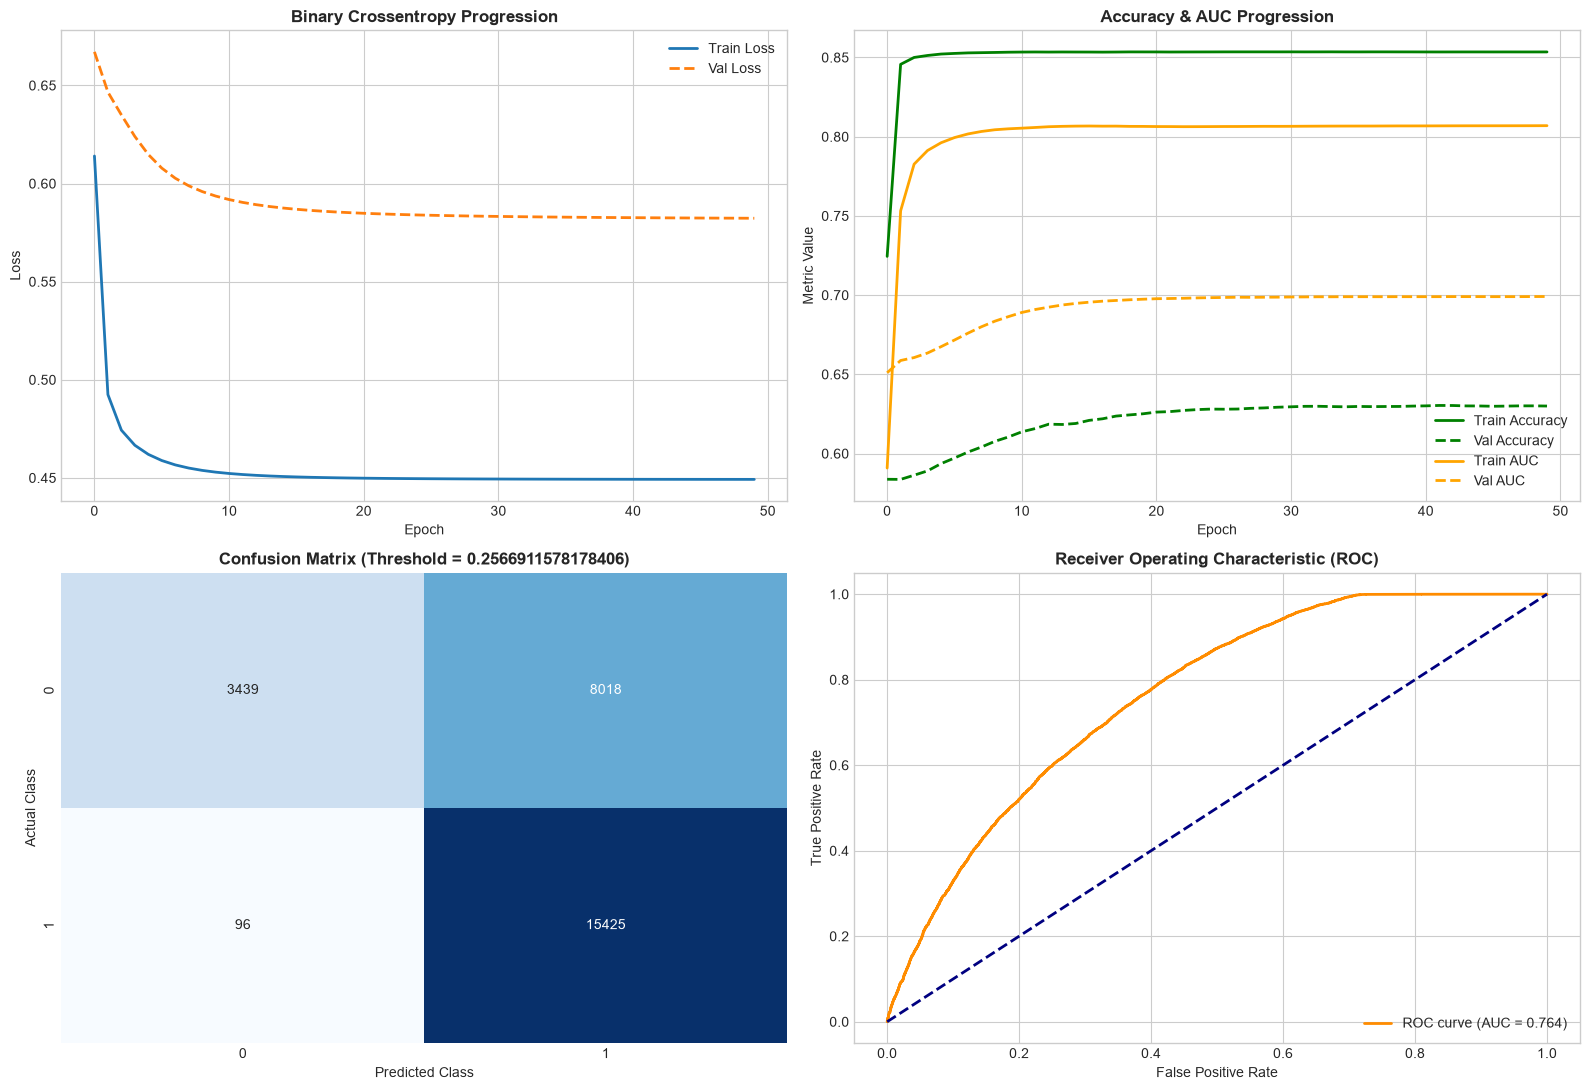

In [12]:
import matplotlib.pyplot as plt

print("X_test:", X_test.shape, "| y_test:", y_test.shape)

df_preds, df_metrics = model_base.evaluate(
    model=history.model,
    history=history,
    X_test=X_test,
    y_test=y_test,
    threshold=UMBRAL,
)

# Estrategias frente al cambio de distribución

Se comparan cuatro configuraciones con el mismo modelo. **La elección se hace con el F1 de validación**; la columna de test solo sirve para confirmar (si eliges mirando test, el test deja de ser independiente).

| Config | Vacas | class_weight | Peso temporal | Umbral |
|---|---|---|---|---|
| A (versión original) | no | balanced | no | 0.5 |
| B | sí | balanced | no | 0.5 |
| C | sí | no | no | val |
| D | sí | no | sí | val |

In [13]:
def entrenar(X_tr, y_tr, X_va, y_va, class_weight=None, sample_weight=None, epochs=50):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    m = LogisticRegression().compile(input_shape=(X_tr.shape[1],))
    m.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=epochs, batch_size=128,
        class_weight=class_weight, sample_weight=sample_weight,
        callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)],
        shuffle=True, verbose=0,
    )
    return m


def correr_config(usar_vacas, usar_cw, vida_media, afinar_umbral):
    idx = [i for i, c in enumerate(feature_names_full) if usar_vacas or c != "vacas_activas_dia"]
    Xtr, Xva, Xte = X_all_full[train][:, idx], X_all_full[val][:, idx], X_all_full[test][:, idx]
    cw = None
    if usar_cw:
        w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
        cw = {0: w[0], 1: w[1]}
    m = entrenar(Xtr, y_train, Xva, y_val, cw, pesos_temporales(fechas[train], vida_media))
    pv, pt = m.predict(Xva, verbose=0).ravel(), m.predict(Xte, verbose=0).ravel()
    thr = mejor_umbral(y_val, pv)[0] if afinar_umbral else 0.5
    mv, mt = metricas(y_val, pv, thr), metricas(y_test, pt, thr)
    return {
        "Umbral": thr,
        "F1 val": mv["F1"], "F1 test": mt["F1"],
        "Lift test": mt["Lift F1"],
        "ROC-AUC test": mt["ROC-AUC"], "PR-AUC test": mt["PR-AUC"],
    }

configs = {
    "A original":            dict(usar_vacas=False, usar_cw=True,  vida_media=None,            afinar_umbral=False),
    "B + vacas":             dict(usar_vacas=True,  usar_cw=True,  vida_media=None,            afinar_umbral=False),
    "C + sin cw, umbral val": dict(usar_vacas=True,  usar_cw=False, vida_media=None,            afinar_umbral=True),
    "D + peso temporal":     dict(usar_vacas=True,  usar_cw=False, vida_media=VIDA_MEDIA_DIAS or 180, afinar_umbral=True),
}
comparacion = pd.DataFrame({k: correr_config(**v) for k, v in configs.items()}).T
print(comparacion.round(4).to_string())
print("\nMejor configuración según F1 de VALIDACIÓN:", comparacion["F1 val"].idxmax())


                        Umbral  F1 val  F1 test  Lift test  ROC-AUC test  PR-AUC test
A original              0.5000  0.6707   0.7932     0.0628        0.7590       0.7678
B + vacas               0.5000  0.6671   0.7901     0.0597        0.7643       0.7800
C + sin cw, umbral val  0.2262  0.6689   0.7918     0.0614        0.7633       0.7811
D + peso temporal       0.2567  0.6693   0.7918     0.0613        0.7641       0.7802

Mejor configuración según F1 de VALIDACIÓN: A original


In [18]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

cols_inf = [c for c in X_full.columns if USAR_VACAS or c != "vacas_activas_dia"]
X_inf = X_full[cols_inf]

pre_inf = construir_preprocesador(X_inf)
Z = pre_inf.fit_transform(X_inf).astype("float64")          # escalado con todo el periodo (análisis explicativo)
Zc = sm.add_constant(Z, has_constant="add")
nombres = list(Zc.columns)

grupos_dia = pd.factorize(df_clean["bloque_tiempo"].dt.floor("D"))[0]

logit = sm.Logit(y_all, Zc)
res = logit.fit(disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": grupos_dia})
res_ing = logit.fit(disp=0, maxiter=200)                    # errores "ingenuos", solo para comparar

df_stats = pd.DataFrame({
    "Feature": nombres,
    "Coeficiente": res.params.values,
    "Std Error (robusto)": res.bse.values,
    "t (z de Wald)": res.tvalues.values,
    "p-value": res.pvalues.values,
})
df_stats["Significativo (p < 0.05)"] = df_stats["p-value"] < 0.05
df_stats = df_stats.reindex(df_stats["t (z de Wald)"].abs().sort_values(ascending=False).index)

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print(f"Observaciones: {int(res.nobs):,} | días (clusters): {grupos_dia.max() + 1} | Pseudo R²: {res.prsquared:.4f}\n")
print(df_stats.to_string(index=False))

Observaciones: 179,847 | días (clusters): 1249 | Pseudo R²: 0.2888

                     Feature  Coeficiente  Std Error (robusto)  t (z de Wald)    p-value  Significativo (p < 0.05)
           vacas_activas_dia       0.8073              0.01129          71.51          0                      True
                       const       -1.874              0.03019         -62.08          0                      True
                    pct_alta        1.101              0.02561             43          0                      True
                    pct_baja       0.9631              0.02272          42.38          0                      True
                  pct_fresca        1.165              0.02829          41.18          0                      True
               pct_extendida       0.6222              0.01517          41.01          0                      True
             patadas_totales       0.1755             0.006064          28.94 3.424e-184                      True
       orden